# 01 — EDA (Khám phá dữ liệu) — chỉ dùng `train.csv`

> Bank Marketing — `train.csv` (sep=`;`). Notebook chạy được **Colab** lẫn **local**.

Checklist gốc (10 bước):
1. Load data  
2. df.head()  
3. df.info()  
4. df.describe()  
5. Kiểm tra missing  
6. Kiểm tra duplicate  
7. Vẽ histogram  
8. Vẽ correlation  
9. Kiểm tra outlier  
10. Kiểm tra class imbalance


## 0. Setup môi trường

> Bạn đã setup trên Colab rồi — cell dưới chỉ import và cấu hình hiển thị. Trên Colab nếu cần mount Drive thì bỏ comment 2 dòng `drive.mount`.


In [15]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 2.2.3 | numpy 2.1.3


## 1. Mount Google Drive


In [16]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Load data — chỉ `train.csv` (không dùng `test.csv`)

In [17]:
# 1. Load data — chỉ train.csv
candidates = [
    Path("my_ds_project/data/raw/train.csv"),
    Path("data/raw/train.csv"),
    Path("../data/raw/train.csv"),
    Path("/content/my_ds_project/data/raw/train.csv"),
    Path("/content/drive/MyDrive/my_ds_project/data/raw/train.csv"),
    Path.cwd() / "my_ds_project" / "data" / "raw" / "train.csv",
]
# tìm file tồn tại, nếu không thấy thì báo
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    # fallback: thử tìm đệ quy
    for p in Path.cwd().rglob("train.csv"):
        if "my_ds_project" in str(p):
            DATA_PATH = p
            break

print(f"DATA_PATH = {DATA_PATH}")
assert DATA_PATH is not None and DATA_PATH.exists(), f"Không tìm thấy train.csv, đã thử: {candidates}"

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Shape: {df.shape}  (rows x cols)")
print(f"Columns: {df.columns.tolist()}")
df.head()

DATA_PATH = /content/drive/MyDrive/my_ds_project/data/raw/train.csv
Shape: (45211, 17)  (rows x cols)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. df.head()

In [18]:
# 2. Xem 5 dòng đầu + tail để cảm nhận dữ liệu
display(df.head())
print("--- tail ---")
display(df.tail(3))
print(f"Shape: {df.shape}")

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


--- tail ---


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


Shape: (45211, 17)


## 4. df.info()

In [19]:
# 3. Kiểu dữ liệu & non-null
df.info()
print("\n--- dtypes ---")
print(df.dtypes.to_string())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

--- dtypes ---
age           int64
job          object
marital      object
education    object
def

## 5. df.describe()

In [20]:
# 4. Thống kê mô tả
print("Numeric describe:")
display(df.describe().T)

print("\nCategorical describe:")
display(df.describe(include='object').T)

print("\nNunique per column:")
display(df.nunique().sort_values().to_frame("nunique"))

print("\nNunique chi tiết cho cột phân loại:")
for c in df.select_dtypes(include='object').columns:
    print(f"- {c}: {df[c].nunique()} values -> {df[c].unique()[:8].tolist()} ...")

Numeric describe:


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0



Categorical describe:


,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922



Nunique per column:


,nunique
housing,2
loan,2
default,2
y,2
contact,3
marital,3
poutcome,4
education,4
month,12
job,12



Nunique chi tiết cho cột phân loại:
- job: 12 values -> ['management', 'technician', 'entrepreneur', 'blue-collar', 'unknown', 'retired', 'admin.', 'services'] ...
- marital: 3 values -> ['married', 'single', 'divorced'] ...
- education: 4 values -> ['tertiary', 'secondary', 'unknown', 'primary'] ...
- default: 2 values -> ['no', 'yes'] ...
- housing: 2 values -> ['yes', 'no'] ...
- loan: 2 values -> ['no', 'yes'] ...
- contact: 3 values -> ['unknown', 'cellular', 'telephone'] ...
- month: 12 values -> ['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan'] ...
- poutcome: 4 values -> ['unknown', 'failure', 'other', 'success'] ...
- y: 2 values -> ['no', 'yes'] ...


## 6. Kiểm tra missing

           missing  pct_%
age              0    0.0
job              0    0.0
marital          0    0.0
education        0    0.0
default          0    0.0
balance          0    0.0
housing          0    0.0
loan             0    0.0
contact          0    0.0
day              0    0.0
month            0    0.0
duration         0    0.0
campaign         0    0.0
pdays            0    0.0
previous         0    0.0
poutcome         0    0.0
y                0    0.0

✅ Không có NaN (missing chuẩn) trong train.csv

Số giá trị 'unknown' (missing ẩn):
  job         :   288  ( 0.64%)
  marital     :     0  ( 0.00%)
  education   :  1857  ( 4.11%)
  default     :     0  ( 0.00%)
  housing     :     0  ( 0.00%)
  loan        :     0  ( 0.00%)
  contact     : 13020  (28.80%)
  poutcome    : 36959  (81.75%)


/tmp/ipykernel_2238/3848318164.py:22: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


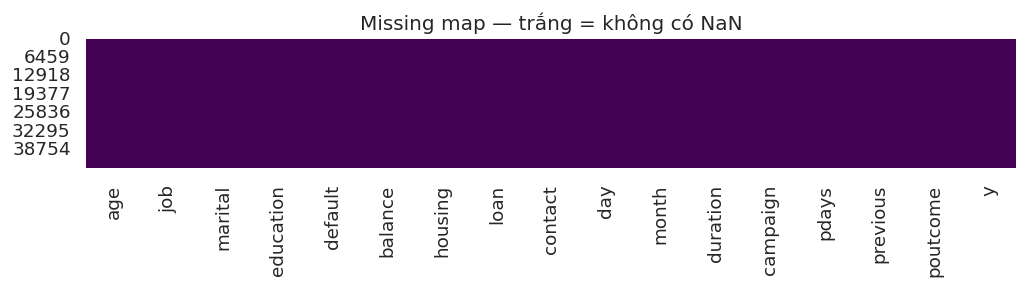

In [21]:
# 5. Kiểm tra missing
missing = df.isnull().sum()
missing_pct = (df.isnull().mean()*100).round(2)
miss_df = pd.DataFrame({"missing": missing, "pct_%": missing_pct})

print(miss_df.to_string())
if (missing==0).all():
    print("\n✅ Không có NaN (missing chuẩn) trong train.csv")

# Bank Marketing có 'unknown' như missing ẩn
unknown_cols = ['job','marital','education','default','housing','loan','contact','poutcome']
print("\nSố giá trị 'unknown' (missing ẩn):")
for c in unknown_cols:
    if c in df.columns:
        n = (df[c]=='unknown').sum()
        print(f"  {c:12s}: {n:5d}  ({n/len(df)*100:5.2f}%)")

# Heatmap missing (sẽ trắng vì không có NaN)
plt.figure(figsize=(10,1.4))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis")
plt.title("Missing map — trắng = không có NaN")
plt.tight_layout()
plt.show()

## 7. Kiểm tra duplicate

In [22]:
# 6. Duplicate
n_dup = df.duplicated().sum()
print(f"Số dòng trùng lặp hoàn toàn: {n_dup} / {len(df)} ({n_dup/len(df)*100:.4f}%)")
if n_dup == 0:
    print("✅ Không có dòng duplicate")
else:
    display(df[df.duplicated(keep=False)].sort_values(df.columns.tolist()).head(10))

# Kiểm tra duplicate theo tập cột khóa (ví dụ: tất cả trừ balance/duration)
# nếu muốn bỏ qua biến liên tục
# print(df.duplicated(subset=[c for c in df.columns if c not in ['balance','duration']]).sum())

Số dòng trùng lặp hoàn toàn: 0 / 45211 (0.0000%)
✅ Không có dòng duplicate


## 8. Vẽ histogram

Numeric cols (7): ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


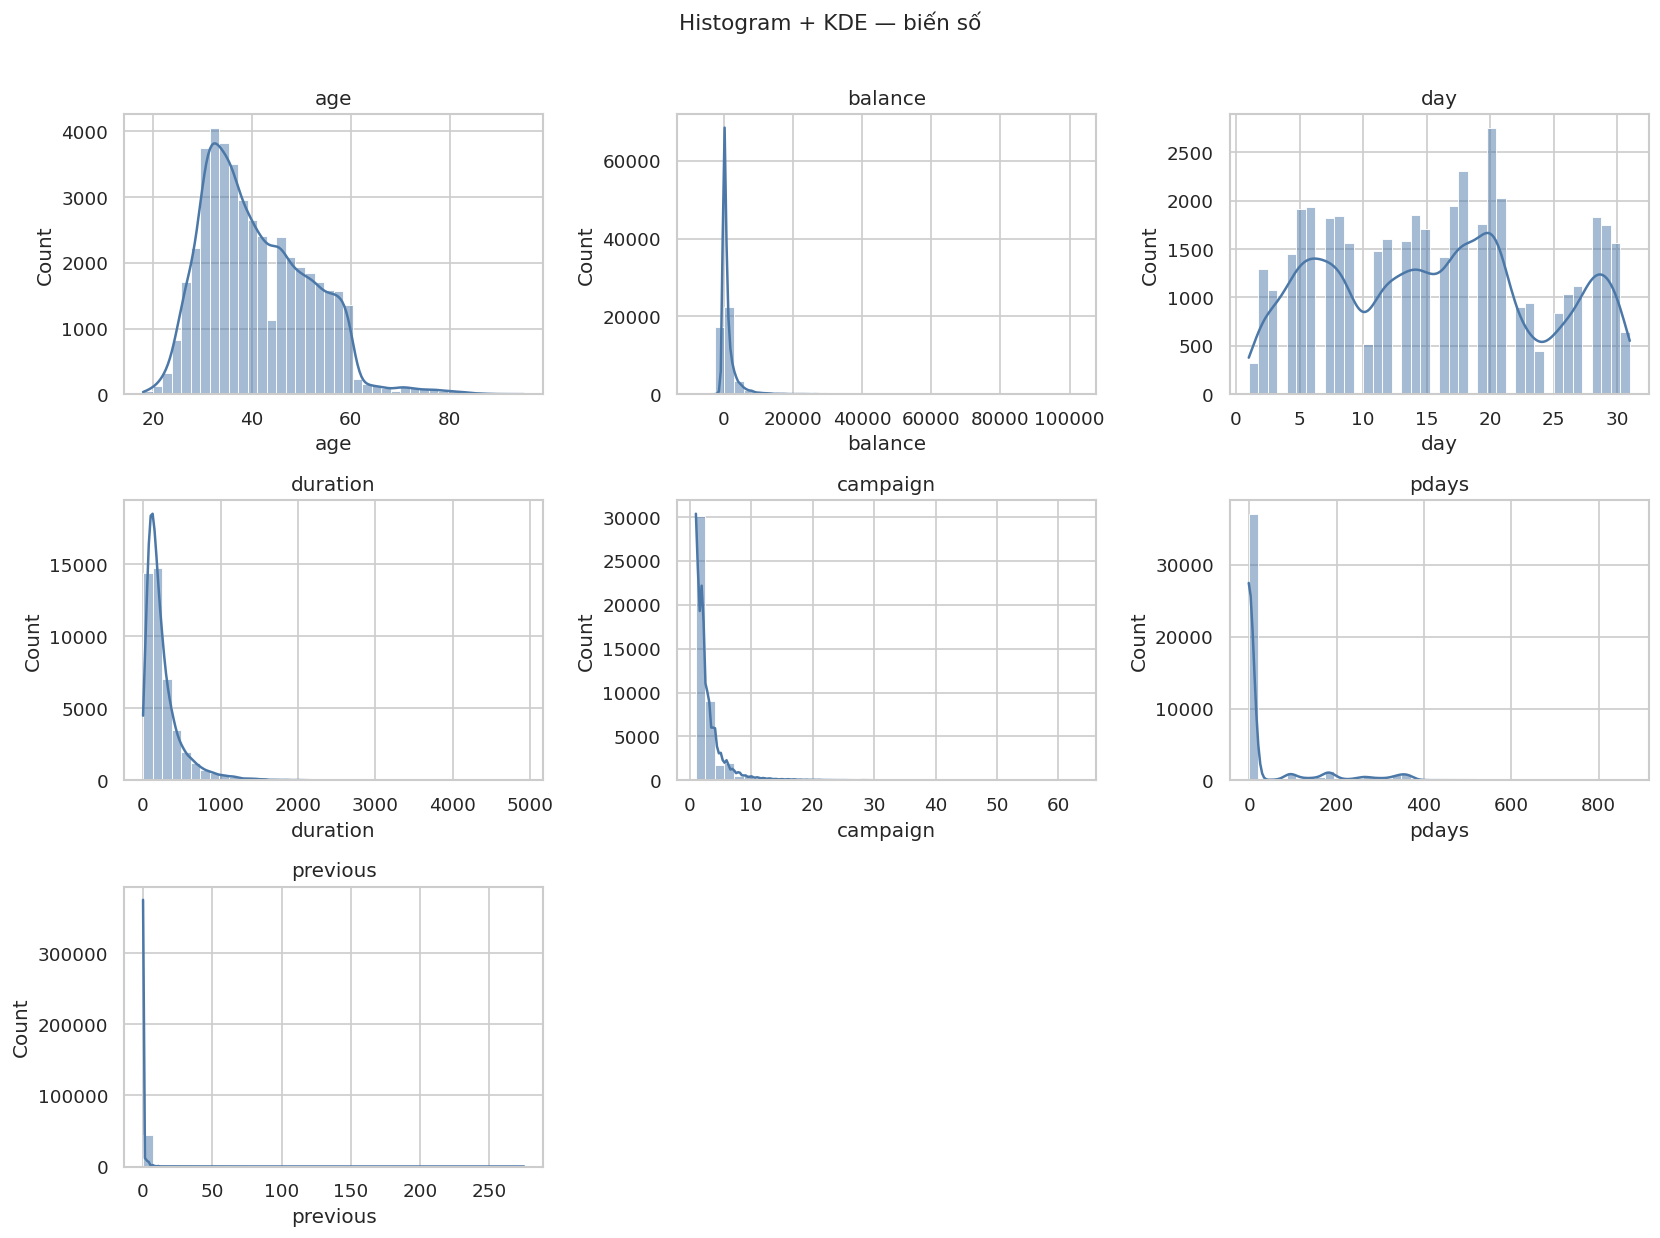

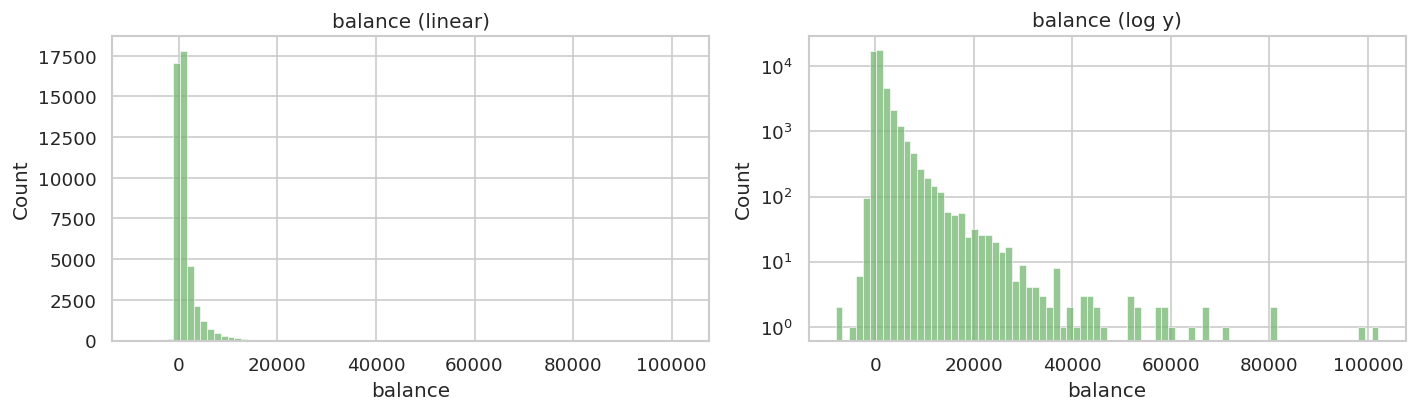

/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


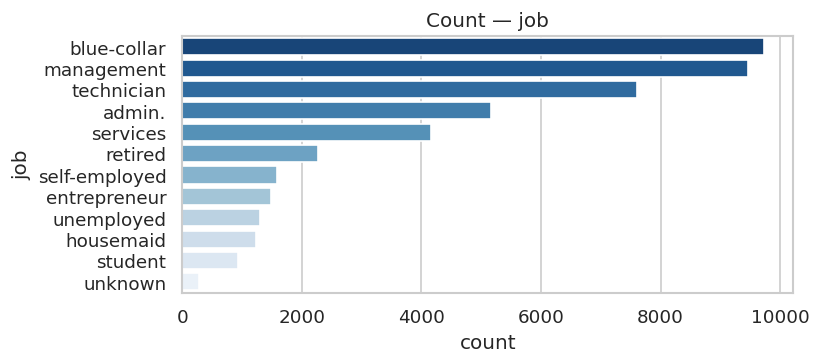

job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


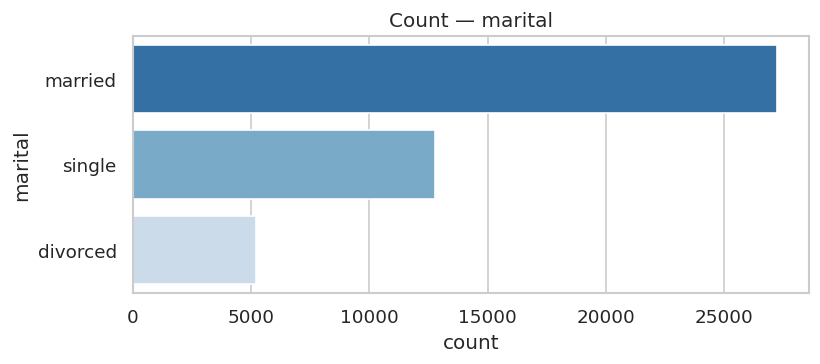

marital
married     27214
single      12790
divorced     5207



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


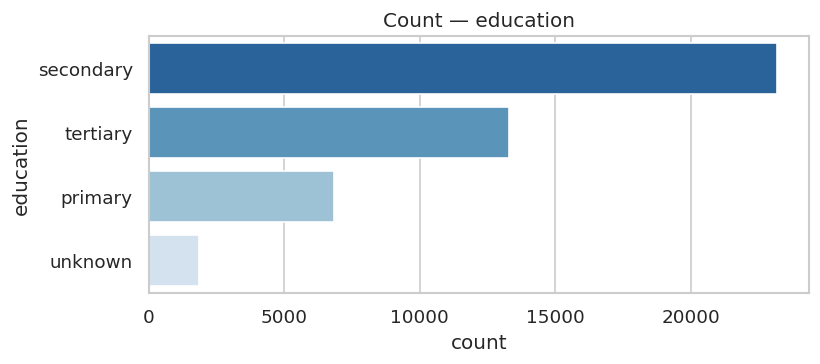

education
secondary    23202
tertiary     13301
primary       6851
unknown       1857



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


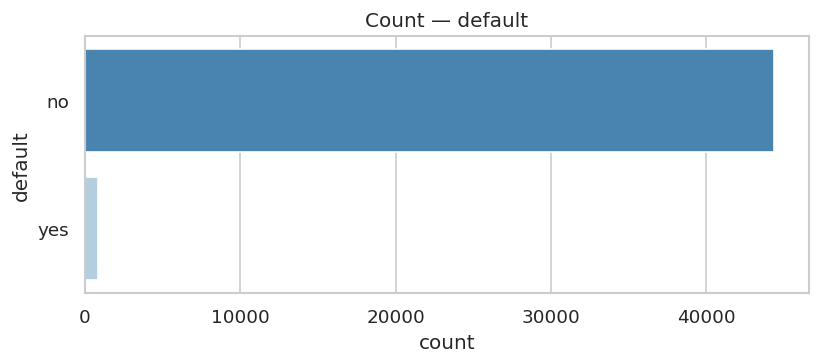

default
no     44396
yes      815



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


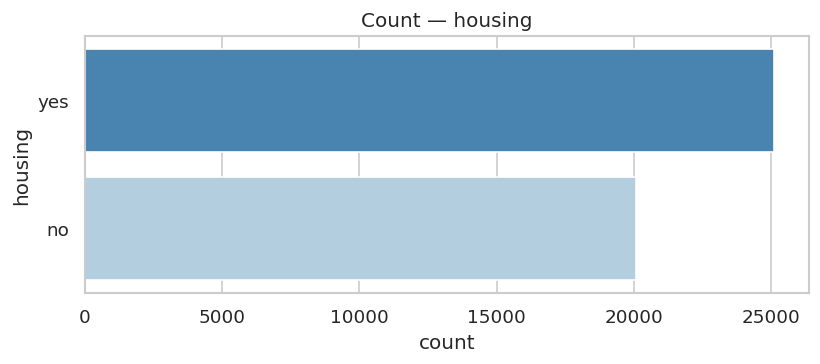

housing
yes    25130
no     20081



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


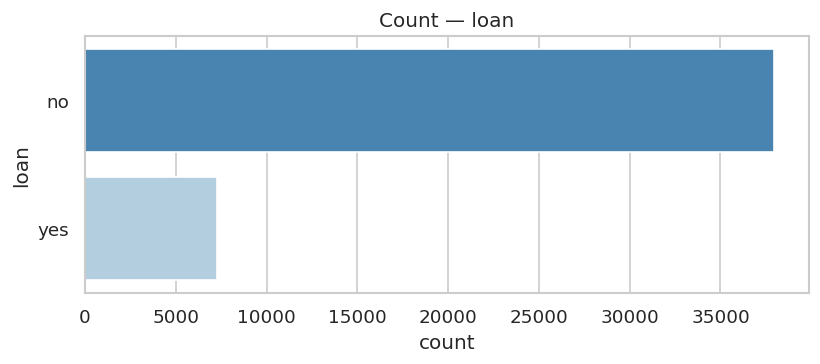

loan
no     37967
yes     7244



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


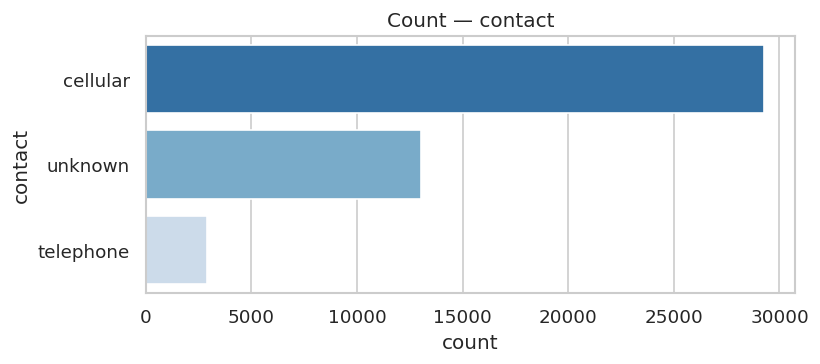

contact
cellular     29285
unknown      13020
telephone     2906



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


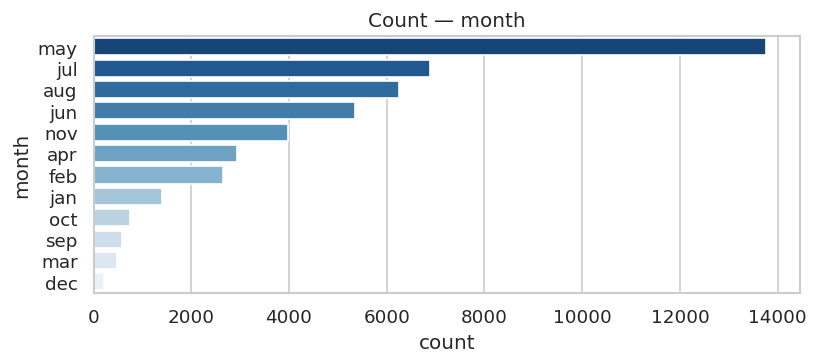

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214



/tmp/ipykernel_2238/1964701018.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=col, data=df, order=order, palette="Blues_r")


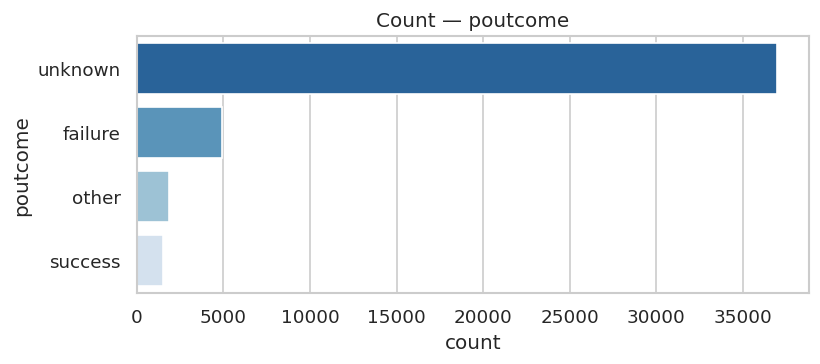

poutcome
unknown    36959
failure     4901
other       1840
success     1511



In [23]:
# 7. Histogram — biến số + countplot cho biến phân loại
num_cols = df.select_dtypes(include='number').columns.tolist()
print(f"Numeric cols ({len(num_cols)}): {num_cols}")

# Histogram + KDE cho numeric
ncols = 3
nrows = (len(num_cols) + ncols - 1)//ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.4*nrows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, bins=40, ax=axes[i], color="#4C78A8")
    axes[i].set_title(col)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
fig.suptitle("Histogram + KDE — biến số", y=1.01, fontsize=13)
plt.tight_layout()
plt.show()

# Riêng balance (outlier rất lớn) — xem log scale
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
sns.histplot(df['balance'], bins=80, ax=ax[0], color="#72B66F")
ax[0].set_title("balance (linear)")
sns.histplot(df['balance'], bins=80, ax=ax[1], color="#72B66F")
ax[1].set_yscale("log")
ax[1].set_title("balance (log y)")
plt.tight_layout()
plt.show()

# Countplot cho biến phân loại (trừ y)
cat_cols = [c for c in df.select_dtypes(include='object').columns if c != 'y']
for col in cat_cols:
    plt.figure(figsize=(7, 3.2))
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, palette="Blues_r")
    plt.title(f"Count — {col}")
    plt.tight_layout()
    plt.show()
    print(df[col].value_counts().to_string())
    print()

## 9. Vẽ correlation

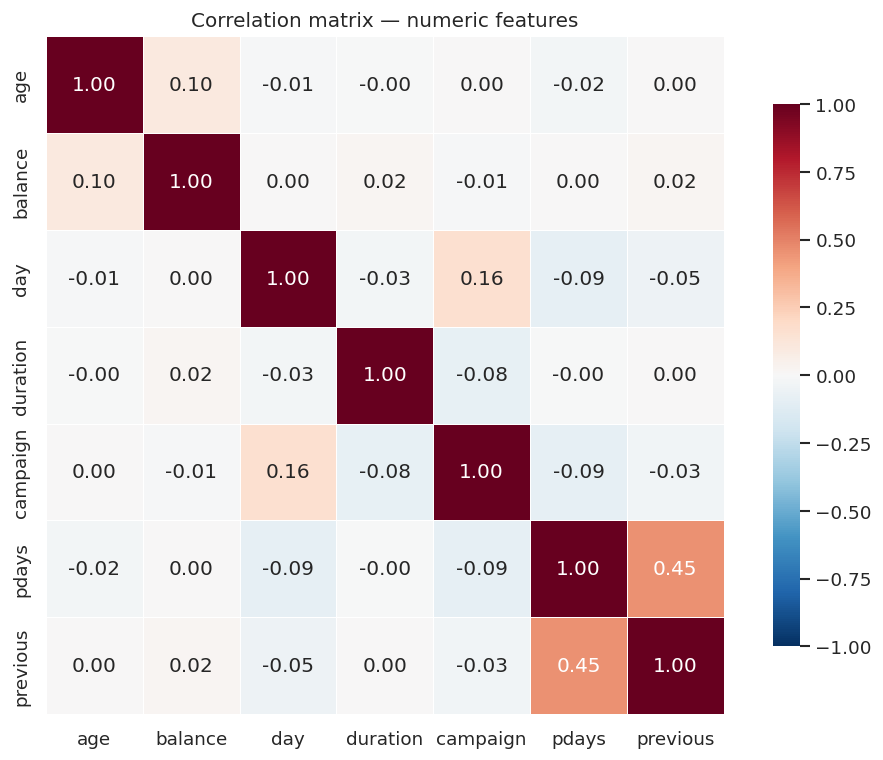

y_bin       1.000000
duration    0.394521
pdays       0.103621
previous    0.093236
balance     0.052838
age         0.025155
day        -0.028348
campaign   -0.073172


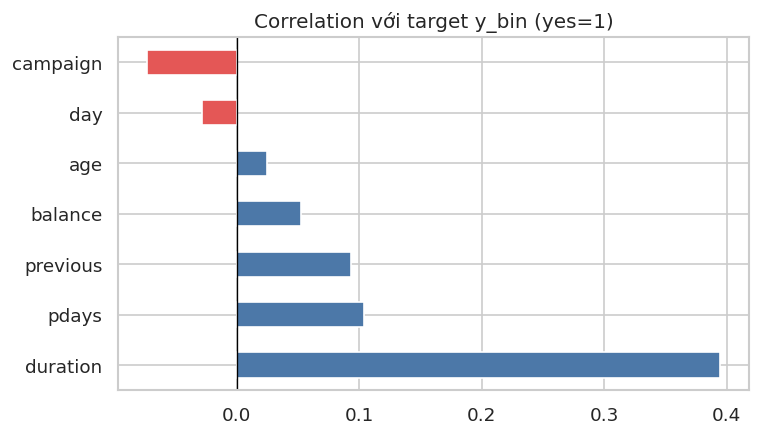


⚠️ Lưu ý: 'duration' tương quan cao nhất với y nhưng là leakage (chỉ biết sau khi gọi) — nên loại khi train.


In [24]:
# 8. Correlation — chỉ trên biến số
corr = df[num_cols].corr(numeric_only=True)

plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink":0.8})
plt.title("Correlation matrix — numeric features")
plt.tight_layout()
plt.show()

# Correlation với target y (encode yes=1)
df_tmp = df.copy()
df_tmp['y_bin'] = (df_tmp['y']=='yes').astype(int)
corr_y = df_tmp[num_cols + ['y_bin']].corr(numeric_only=True)['y_bin'].sort_values(ascending=False)
print(corr_y.to_string())

plt.figure(figsize=(6.5, 3.8))
vals = corr_y.drop('y_bin')
colors = ["#E45756" if v < 0 else "#4C78A8" for v in vals]
vals.plot(kind='barh', color=colors)
plt.title("Correlation với target y_bin (yes=1)")
plt.axvline(0, color='black', linewidth=.8)
plt.tight_layout()
plt.show()

print("\n⚠️ Lưu ý: 'duration' tương quan cao nhất với y nhưng là leakage (chỉ biết sau khi gọi) — nên loại khi train.")

## 10. Kiểm tra outlier

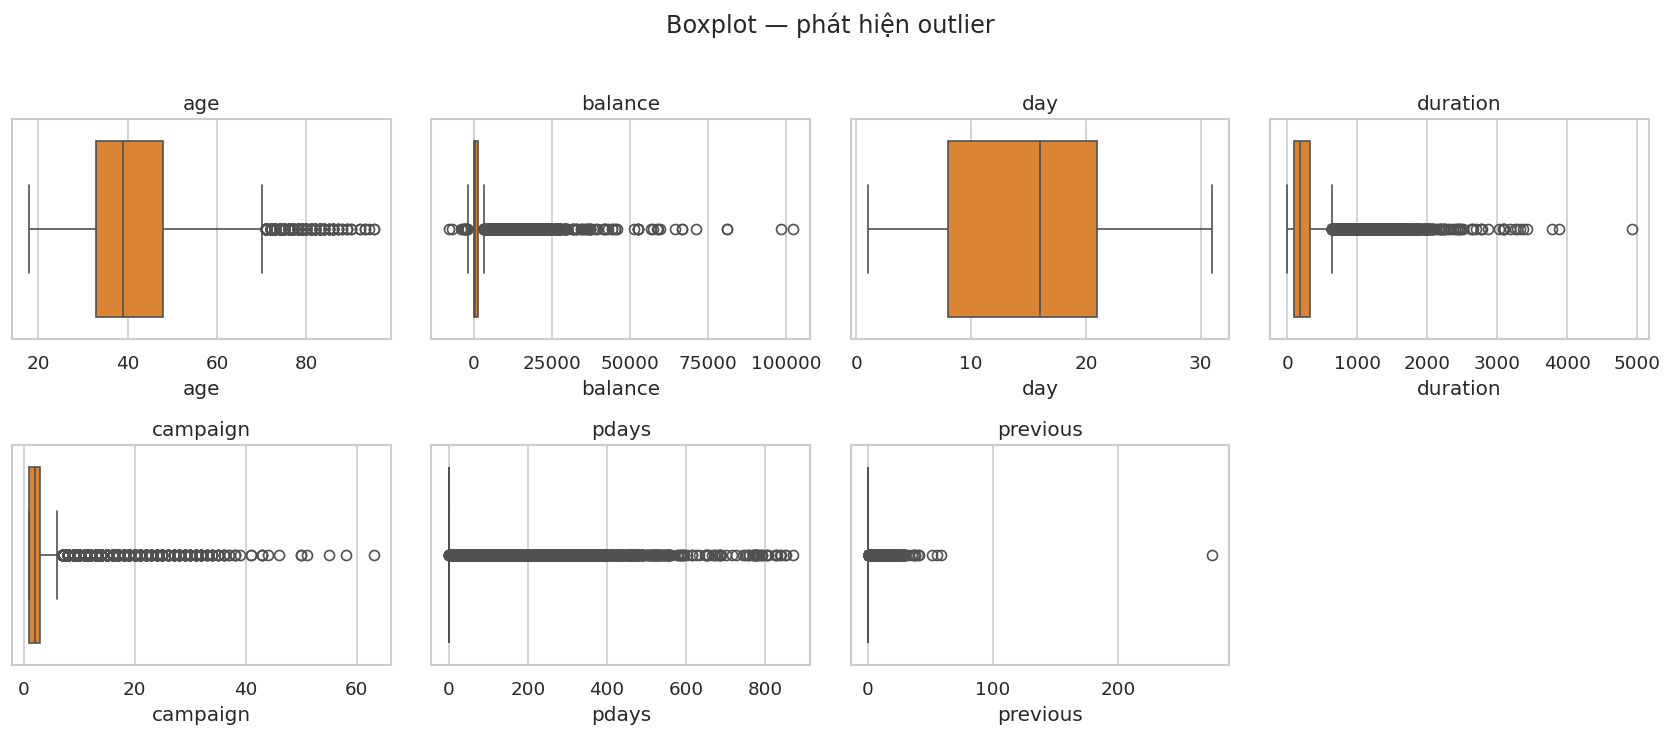

,Q1,Q3,IQR,low,high,n_low,n_high,pct_out_%
age,33.0,48.0,15.0,10.5,70.5,0.0,487.0,1.08
balance,72.0,1428.0,1356.0,-1962.0,3462.0,17.0,4712.0,10.46
day,8.0,21.0,13.0,-11.5,40.5,0.0,0.0,0.00
duration,103.0,319.0,216.0,-221.0,643.0,0.0,3235.0,7.16
campaign,1.0,3.0,2.0,-2.0,6.0,0.0,3064.0,6.78
pdays,-1.0,-1.0,0.0,-1.0,-1.0,0.0,8257.0,18.26
previous,0.0,0.0,0.0,0.0,0.0,0.0,8257.0,18.26



Chi tiết bounds:
balance    | Q1=    72.0 Q3=  1428.0 IQR=  1356.0 | bounds=(-1962.0, 3462.0) | max=102127
duration   | Q1=   103.0 Q3=   319.0 IQR=   216.0 | bounds=(-221.0, 643.0) | max=4918
campaign   | Q1=     1.0 Q3=     3.0 IQR=     2.0 | bounds=(-2.0, 6.0) | max=63
pdays      | Q1=    -1.0 Q3=    -1.0 IQR=     0.0 | bounds=(-1.0, -1.0) | max=871
previous   | Q1=     0.0 Q3=     0.0 IQR=     0.0 | bounds=(0.0, 0.0) | max=275
age        | Q1=    33.0 Q3=    48.0 IQR=    15.0 | bounds=(10.5, 70.5) | max=95

pdays == -1 : 36954 (81.7%) — mã đặc biệt 'chưa từng liên hệ'
pdays==-1 & poutcome=='unknown': 36954 (gần như trùng khớp)


In [25]:
# 9. Outlier — boxplot + IQR
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(x=df[col], ax=axes[i], color="#F58518")
    axes[i].set_title(col)
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Boxplot — phát hiện outlier", y=1.02)
plt.tight_layout()
plt.show()

def iqr_stats(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_low = (s < low).sum()
    n_high = (s > high).sum()
    return pd.Series({"Q1":q1,"Q3":q3,"IQR":iqr,"low":low,"high":high,
                      "n_low":n_low,"n_high":n_high,"pct_out_%": round((n_low+n_high)/len(s)*100,2)})

outlier_df = df[num_cols].apply(iqr_stats).T
display(outlier_df)

print("\nChi tiết bounds:")
for col in ['balance','duration','campaign','pdays','previous','age']:
    q1, q3 = df[col].quantile([0.25,0.75])
    iqr = q3-q1
    print(f"{col:10s} | Q1={q1:8.1f} Q3={q3:8.1f} IQR={iqr:8.1f} | bounds=({q1-1.5*iqr:.1f}, {q3+1.5*iqr:.1f}) | max={df[col].max()}")

print(f"\npdays == -1 : {(df['pdays']==-1).sum()} ({(df['pdays']==-1).mean()*100:.1f}%) — mã đặc biệt 'chưa từng liên hệ'")
print(f"pdays==-1 & poutcome=='unknown': {((df['pdays']==-1) & (df['poutcome']=='unknown')).sum()} (gần như trùng khớp)")

## 11. Kiểm tra class imbalance

,count,pct_%
y,,
no,39922,88.3
yes,5289,11.7


Imbalance ratio (no:yes) = 7.5:1  (no=88.3%, yes=11.7%)


/tmp/ipykernel_2238/2014220180.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='y', data=df, ax=axes[0], palette=["#4C78A8","#E45756"], order=['no','yes'])


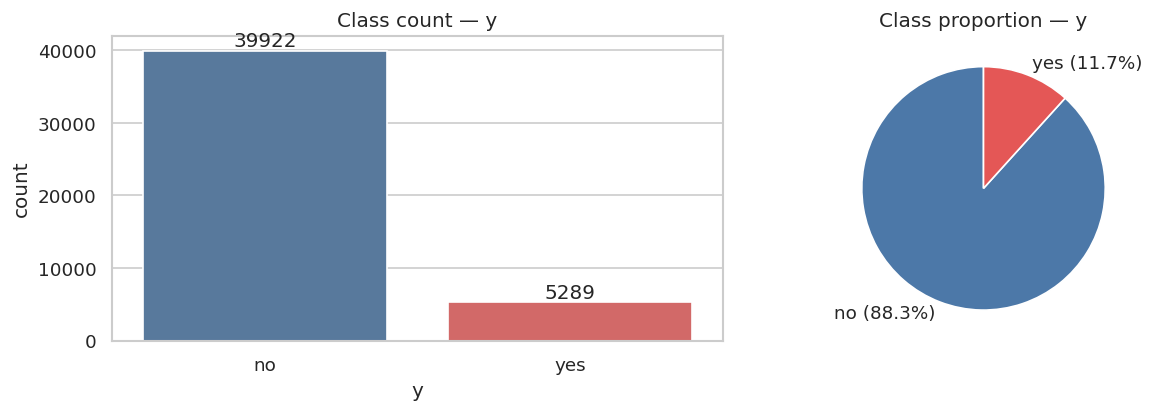

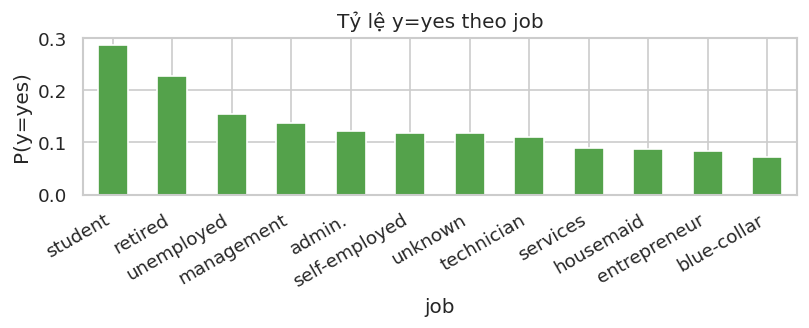

job
student          0.287
retired          0.228
unemployed       0.155
management       0.138
admin.           0.122
self-employed    0.118
unknown          0.118
technician       0.111
services         0.089
housemaid        0.088
entrepreneur     0.083
blue-collar      0.073



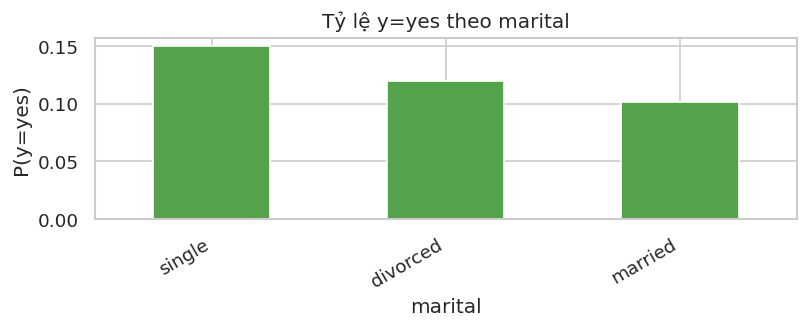

marital
single      0.149
divorced    0.119
married     0.101



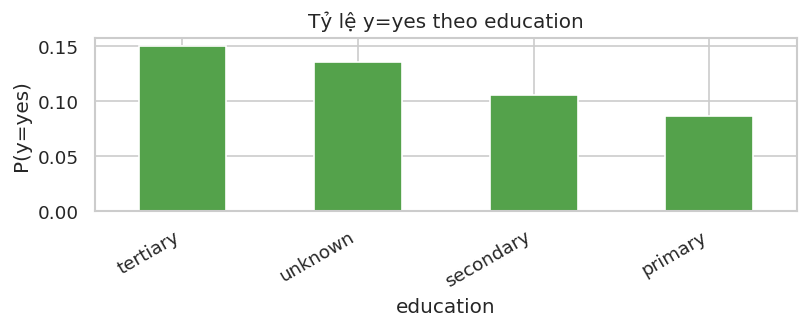

education
tertiary     0.150
unknown      0.136
secondary    0.106
primary      0.086



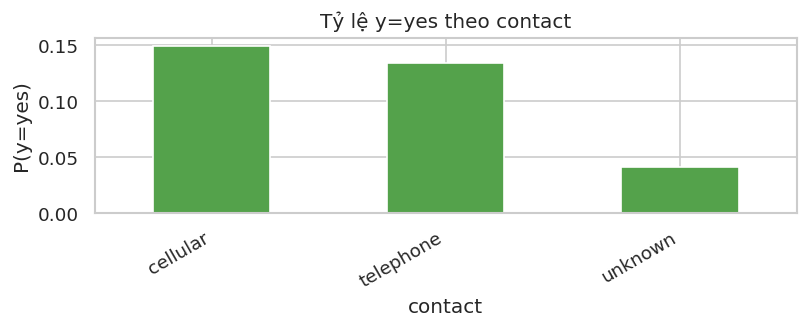

contact
cellular     0.149
telephone    0.134
unknown      0.041



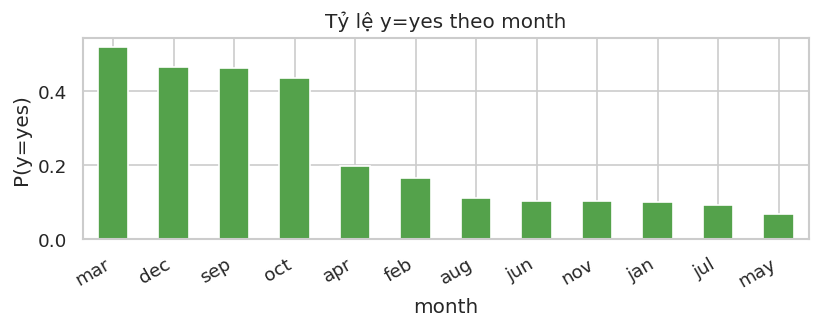

month
mar    0.520
dec    0.467
sep    0.465
oct    0.438
apr    0.197
feb    0.166
aug    0.110
jun    0.102
nov    0.102
jan    0.101
jul    0.091
may    0.067



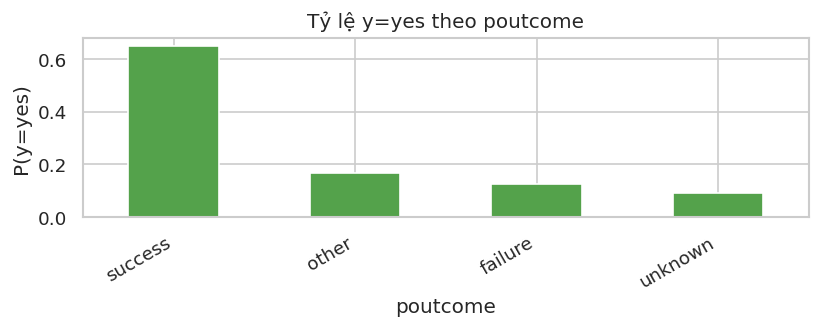

poutcome
success    0.647
other      0.167
failure    0.126
unknown    0.092

Gợi ý cho bước modeling:
  - Imbalance ~88/12 (≈7.6:1) → dùng class_weight='balanced', SMOTE, hoặc stratified split
  - Ưu tiên F1 / PR-AUC / Recall(yes) thay vì Accuracy thuần túy
  - Loại 'duration' khỏi features để tránh leakage


In [26]:
# 10. Class imbalance — target y
counts = df['y'].value_counts()
pct = df['y'].value_counts(normalize=True)*100
summary = pd.DataFrame({"count": counts, "pct_%": pct.round(2)})
display(summary)
print(f"Imbalance ratio (no:yes) = {counts['no']/counts['yes']:.1f}:1  (no={pct['no']:.1f}%, yes={pct['yes']:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.countplot(x='y', data=df, ax=axes[0], palette=["#4C78A8","#E45756"], order=['no','yes'])
for c in axes[0].containers:
    axes[0].bar_label(c)
axes[0].set_title("Class count — y")
axes[1].pie(counts.values, labels=[f"{i} ({pct[i]:.1f}%)" for i in counts.index],
            autopct='', startangle=90, colors=["#4C78A8","#E45756"], wedgeprops={"edgecolor":"white"})
axes[1].set_title("Class proportion — y")
plt.tight_layout()
plt.show()

# Tỷ lệ y=yes theo từng biến phân loại — tìm segment có conversion cao
cat_for_target = ['job','marital','education','contact','month','poutcome']
for col in cat_for_target:
    rate = df.groupby(col, observed=True)['y'].apply(lambda s: (s=='yes').mean()).sort_values(ascending=False)
    plt.figure(figsize=(7, 2.9))
    rate.plot(kind='bar', color="#54A24B")
    plt.ylabel("P(y=yes)")
    plt.title(f"Tỷ lệ y=yes theo {col}")
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.show()
    print(rate.round(3).to_string())
    print()

print("Gợi ý cho bước modeling:")
print("  - Imbalance ~88/12 (≈7.6:1) → dùng class_weight='balanced', SMOTE, hoặc stratified split")
print("  - Ưu tiên F1 / PR-AUC / Recall(yes) thay vì Accuracy thuần túy")
print("  - Loại 'duration' khỏi features để tránh leakage")

### Tổng kết EDA (train.csv)

- **Shape**: 45,211 × 17, không có NaN, không có duplicate
- **Missing ẩn**: nhiều `unknown` ở `poutcome` (~82%), `contact` (~30%), `job`/`education` — cần xử lý ở preprocessing
- **Numeric**: `balance`, `duration`, `campaign`, `previous` lệch phải mạnh; `pdays=-1` là mã đặc biệt (81.7% data, trùng với `poutcome=unknown`)
- **Tương quan**: các biến số tương quan yếu với nhau; `duration` tương quan cao nhất với `y` nhưng là leakage
- **Imbalance**: `y=no` 88.3% vs `yes` 11.7% (~7.6:1) → cần chiến lược cân bằng khi train
- **Next**: sang `02_preprocessing.ipynb` để xử lý `unknown`, outlier, encoding, scaling, và loại `duration`.
